# Class-conditional GAN training
The generator concatenates latent noise with a learned label embedding, projects to `128x7x7`, then upsamples twice to a `1x28x28` Tanh output. The discriminator concatenates a learned spatial label map with the image. Convolutions reuse local stroke structure more effectively than the starter's fully connected layers. Both models learn from real **MNIST training data only**.

In [1]:
import sys
from pathlib import Path
import torch
import matplotlib.pyplot as plt
STARTER = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'model/cgan.py').is_file())
sys.path.insert(0, str(STARTER))
from model.cgan import Generator, Discriminator
from training.train_cgan import train_cgan
from data_utils.dataloader import get_mnist_loaders
from utils.checkpoint import CHECKPOINT_DIR, OUTPUT_DIR
from utils.generation import generate_digits, load_generator
from utils.runtime import setup
from utils.visualize import show_batch, latent_walk
device = setup(42)
print('Device:', device)

Device: cuda


In [2]:
z_dim, num_classes, batch_size = 100, 10, 128
epochs, learning_rate = 50, 2e-4
train_loader, _ = get_mnist_loaders(batch_size, pin_memory=device.type == 'cuda')
generator = Generator(z_dim, num_classes).to(device)
discriminator = Discriminator(num_classes).to(device)
optimizer_G = torch.optim.Adam(generator.parameters(), lr=learning_rate, betas=(0.5, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=learning_rate, betas=(0.5, 0.999))
criterion = torch.nn.BCEWithLogitsLoss()

## Adversarial objective and separate updates
For each batch minimize `L_D = (BCE(D(x,y),1) + BCE(D(G(z,y),y),0))/2`, detaching generated images for the discriminator step. Then minimize the non-saturating BCE generator objective `L_G = BCE(D(G(z,y),y),1)`, freezing discriminator parameters but propagating gradients through its input. This is the standard practical GAN minimax game; non-saturating G loss avoids weak gradients early in training. `BCEWithLogitsLoss` combines sigmoid and BCE stably, so D deliberately returns **logits**, not sigmoid probabilities.

The reusable loop prints example-weighted epoch losses, writes history every epoch and saves **distinct** generator/discriminator files every ten epochs and at completion. CUDA uses automatic mixed precision; CPU/MPS use float32. Finite-loss checks fail loudly. These curves diagnose training but do not alone prove fidelity or conditional correctness.

Epoch 1/50: D=0.4931, G=1.4245
Epoch 2/50: D=0.5565, G=0.9619
Epoch 3/50: D=0.5710, G=0.9935
Epoch 4/50: D=0.5757, G=0.9656
Epoch 5/50: D=0.5481, G=1.0171
Epoch 6/50: D=0.5565, G=1.0110
Epoch 7/50: D=0.5822, G=0.9705
Epoch 8/50: D=0.6188, G=0.9057
Epoch 9/50: D=0.6374, G=0.8653
Epoch 10/50: D=0.6574, G=0.8331
Epoch 11/50: D=0.6617, G=0.8185
Epoch 12/50: D=0.6675, G=0.8052
Epoch 13/50: D=0.6720, G=0.8001
Epoch 14/50: D=0.6749, G=0.7954
Epoch 15/50: D=0.6769, G=0.7923
Epoch 16/50: D=0.6762, G=0.7857
Epoch 17/50: D=0.6776, G=0.7897
Epoch 18/50: D=0.6775, G=0.7886
Epoch 19/50: D=0.6772, G=0.7805
Epoch 20/50: D=0.6775, G=0.7826
Epoch 21/50: D=0.6770, G=0.7814
Epoch 22/50: D=0.6775, G=0.7895
Epoch 23/50: D=0.6771, G=0.7869
Epoch 24/50: D=0.6747, G=0.7829
Epoch 25/50: D=0.6745, G=0.7856
Epoch 26/50: D=0.6741, G=0.7865
Epoch 27/50: D=0.6726, G=0.7873
Epoch 28/50: D=0.6715, G=0.7832
Epoch 29/50: D=0.6706, G=0.7903
Epoch 30/50: D=0.6702, G=0.7877
Epoch 31/50: D=0.6690, G=0.7900
Epoch 32/50: D=0.

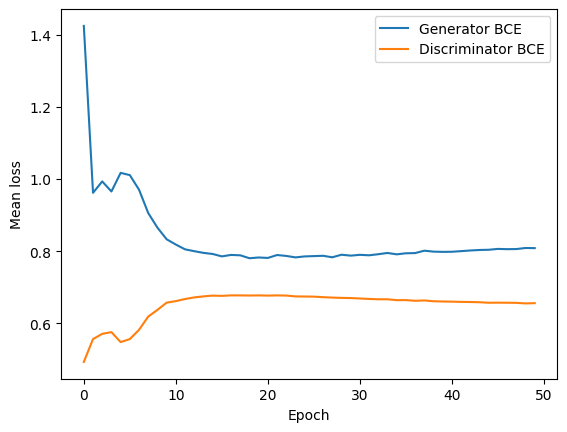

In [3]:
history = train_cgan(
    generator, discriminator, train_loader, optimizer_G, optimizer_D,
    criterion, device, z_dim, num_classes, epochs=epochs,
    checkpoint_dir=CHECKPOINT_DIR, save_every=10,
)
plt.plot([row['g_loss'] for row in history], label='Generator BCE')
plt.plot([row['d_loss'] for row in history], label='Discriminator BCE')
plt.xlabel('Epoch'); plt.ylabel('Mean loss'); plt.legend(); plt.show()

## Generated digits 0-9
Each row below holds eight independently sampled images of one requested digit. Labels show the conditioning input, not a classifier's prediction. Inspect every row for recognizable digits and style variation; if samples are poor, train longer or tune using training/validation evidence, not the real test set. No trained quality is claimed until this cell is run and saved.

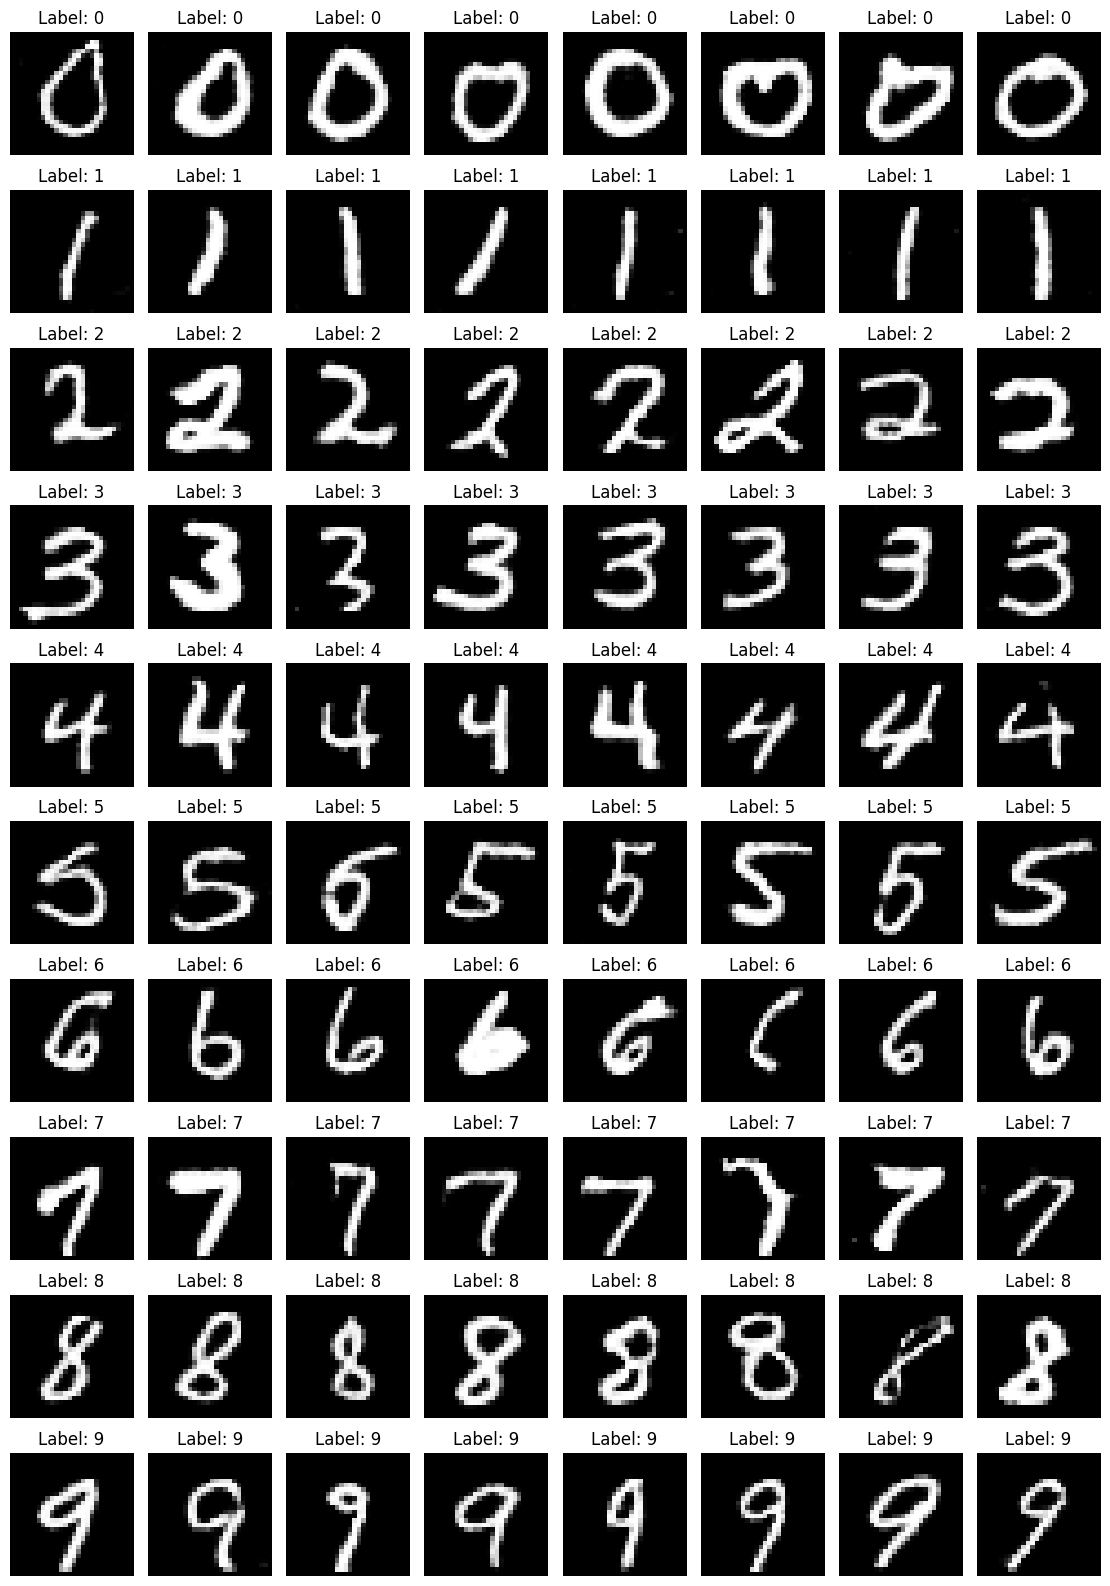

In [4]:
generator = load_generator(CHECKPOINT_DIR / 'cgan_generator_epochfinal.pt', 'cgan', device)
labels = torch.arange(10).repeat_interleave(8)
images, labels = generate_digits(generator, 'cgan', labels, device, seed=100)
figure = show_batch(images, labels, n=80, columns=8)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
figure.savefig(OUTPUT_DIR / 'cgan_digits.png', dpi=150)

## Stand-out: latent-space walk
Hold the label fixed and interpolate linearly between two seeded Gaussian noise vectors. A smooth visual change suggests a continuous style representation; interpolation can pass through lower-probability latent regions, and smoothness is not a guarantee of correct digit identity.

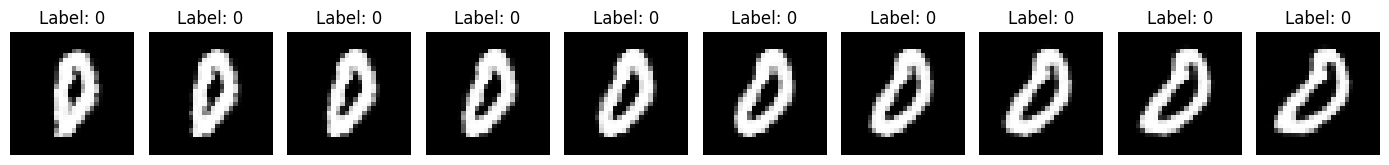

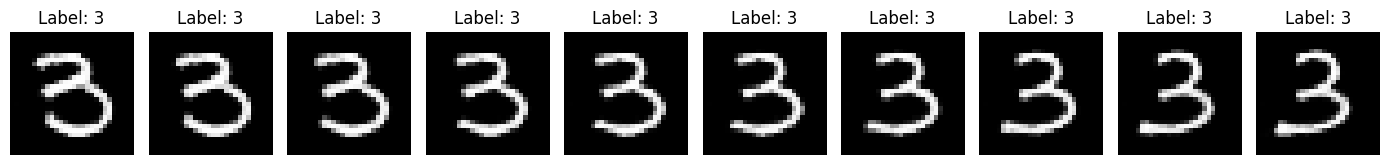

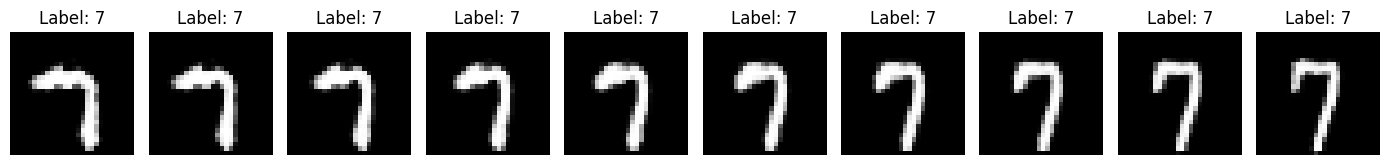

In [5]:
for digit in (0, 3, 7):
    walk, walk_labels = latent_walk(generator, digit, device, steps=10, seed=42 + digit)
    figure = show_batch(walk, walk_labels, n=10, columns=10)
    figure.savefig(OUTPUT_DIR / f'latent_walk_{digit}.png', dpi=150)